# Lab 7: Explainable AI, Adversarial AI and Advanced Applications
## Experiment 1: Explainable AI using Grad-CAM on CIFAR-10

This notebook demonstrates **Explainable AI (XAI)** in computer vision by implementing **Gradient-Weighted Class Activation Mapping (Grad-CAM)** from first principles using PyTorch hooks.

### Key Objectives:
1. Load and inspect the official **CIFAR-10** image dataset from the local repository directory.
2. Construct and train a lightweight Convolutional Neural Network (CNN) tailored for fast CPU execution.
3. Understand model interpretability and the semantic gap in deep vision models.
4. Implement forward and backward PyTorch hooks to capture feature maps and gradients from the final convolutional layer.
5. Compute Grad-CAM importance weights via Global Average Pooling (GAP) of gradients.
6. Generate a normalized class activation heatmap and overlay it onto original test images.
7. Interpret the visual explanations and analyze the strengths and limitations of Grad-CAM.


---
### 1. Import Essential Libraries and Configure Environment
We import PyTorch, torchvision, NumPy, and Matplotlib. We verify library versions, confirm CPU execution, and configure dynamic relative paths for saving figures.


In [1]:
from pathlib import Path
import time
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.datasets as dset
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Subset

# Set reproducible random seeds
torch.manual_seed(42)
np.random.seed(42)

print(f"PyTorch Version     : {torch.__version__}")
print(f"Torchvision Version : {torchvision.__version__}")
device = torch.device("cpu")
print(f"Execution Device    : {device}")

# Output path management
OUTPUT_DIR = Path("Lab7/outputs") if Path("Lab7").exists() else Path("outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Output Directory    : {OUTPUT_DIR.resolve()}")


PyTorch Version     : 2.15.0+cpu
Torchvision Version : 0.29.2+cpu
Execution Device    : cpu
Output Directory    : /home/jeet/Desktop/Artificial_Intelligence/Lab7/outputs


---
### 2. Loading the Existing CIFAR-10 Dataset
We load the CIFAR-10 dataset from the shared repository directory (`datasets/`). The dataset contains 60,000 $32 \times 32$ color images spanning 10 distinct object classes.


In [2]:
# Locate CIFAR-10 directory
DATA_DIR = Path("datasets") if Path("datasets").exists() else Path("../datasets")

if (DATA_DIR / "cifar-10-python" / "cifar-10-batches-py").exists():
    cifar_root = DATA_DIR / "cifar-10-python"
elif (DATA_DIR / "cifar-10-batches-py").exists():
    cifar_root = DATA_DIR
else:
    raise FileNotFoundError(f"CIFAR-10 dataset not found in {DATA_DIR}.")

print(f"Loading CIFAR-10 from: {cifar_root}")

# Standard CIFAR-10 normalization
transform_train = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616))
])

# Unnormalized transform for clean plotting
transform_raw = transforms.Compose([transforms.ToTensor()])

trainset = dset.CIFAR10(root=str(cifar_root), train=True, download=False, transform=transform_train)
testset_norm = dset.CIFAR10(root=str(cifar_root), train=False, download=False, transform=transform_train)
testset_raw = dset.CIFAR10(root=str(cifar_root), train=False, download=False, transform=transform_raw)

classes = trainset.classes
print(f"Total Training Images : {len(trainset)}")
print(f"Total Testing Images  : {len(testset_norm)}")
print(f"CIFAR-10 Class Labels : {classes}")


Loading CIFAR-10 from: ../datasets/cifar-10-python


Total Training Images : 50000
Total Testing Images  : 10000
CIFAR-10 Class Labels : ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


---
### 3. Visualizing Sample CIFAR-10 Images
We inspect representative samples across classes to observe natural variations in orientation, lighting, and background.


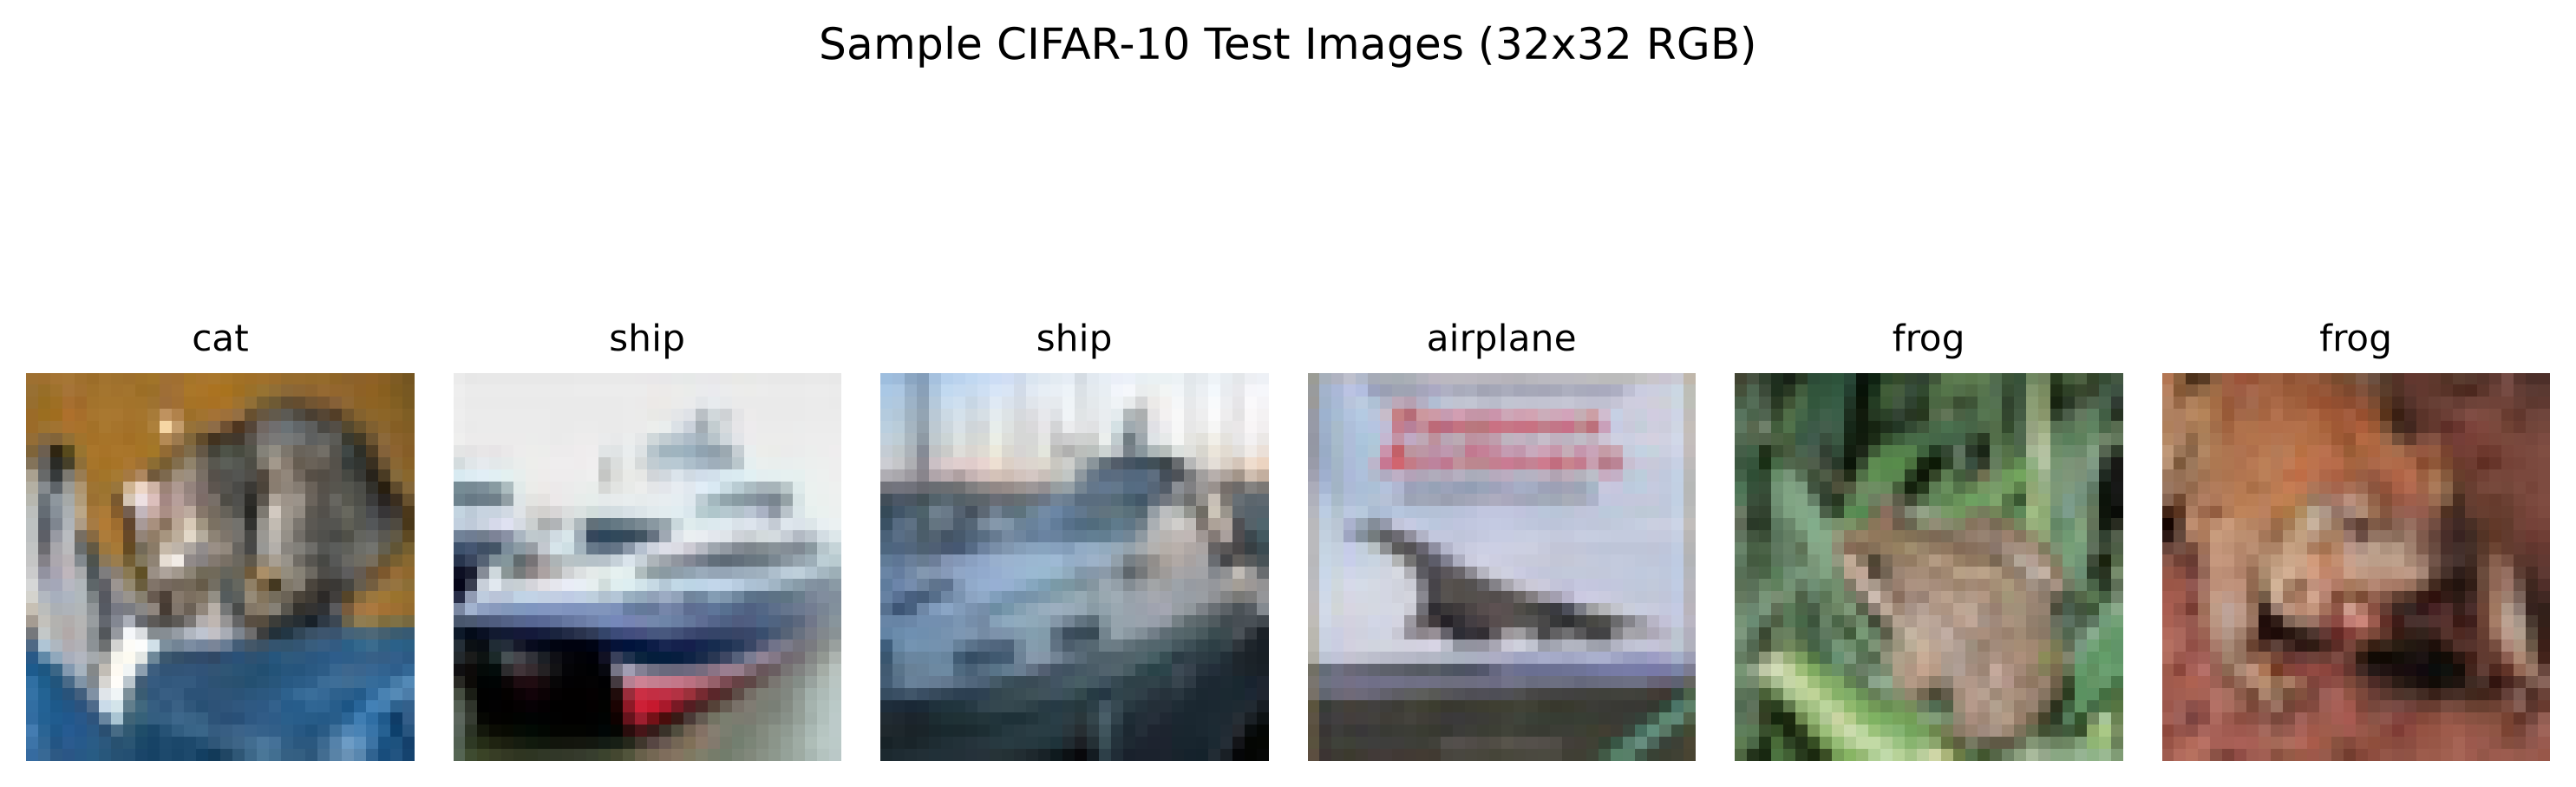

In [3]:
plt.figure(figsize=(10, 4), dpi=300)
for i in range(6):
    img, label = testset_raw[i]
    np_img = img.permute(1, 2, 0).numpy()
    plt.subplot(1, 6, i + 1)
    plt.imshow(np_img)
    plt.title(classes[label], fontsize=10)
    plt.axis("off")
plt.suptitle("Sample CIFAR-10 Test Images (32x32 RGB)", fontsize=12)
plt.tight_layout()
plt.show()


---
### 4. Building a Lightweight CNN Architecture for CPU Execution
We define a compact, transparent CNN containing two convolutional blocks and a linear classification head. The second convolutional layer (`features[3]`) serves as our target layer for Grad-CAM.


In [4]:
class CIFAR10CNN(nn.Module):
    """Compact CNN with feature extractor and classification head."""
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            # Block 1: 32x32 -> 16x16
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            # Block 2: 16x16 -> 8x8 (Target Conv Layer: index 3)
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 8 * 8, 64),
            nn.ReLU(),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

model = CIFAR10CNN()
print("Model Architecture:\n", model)
total_params = sum(p.numel() for p in model.parameters())
print(f"Total Trainable Parameters: {total_params:,}")


Model Architecture:
 CIFAR10CNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2048, out_features=64, bias=True)
    (2): ReLU()
    (3): Linear(in_features=64, out_features=10, bias=True)
  )
)
Total Trainable Parameters: 136,874


---
### 5. Training the CNN on a CPU-Friendly Subset
To balance fast execution with genuine learned representations, we train the model on a 3,000-image subset for 4 epochs using the Adam optimizer.


In [5]:
train_subset = Subset(trainset, range(3000))
train_loader = DataLoader(train_subset, batch_size=64, shuffle=True)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.003)

print("Starting CPU training on 3,000 CIFAR-10 images (4 epochs)...")
start_time = time.time()

for epoch in range(1, 5):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in train_loader:
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = (correct / total) * 100
    print(f"Epoch [{epoch}/4] - Loss: {epoch_loss:.4f} | Accuracy: {epoch_acc:.2f}%")

print(f"Training completed in {time.time() - start_time:.2f} seconds.")


Starting CPU training on 3,000 CIFAR-10 images (4 epochs)...


Epoch [1/4] - Loss: 2.0317 | Accuracy: 25.20%


Epoch [2/4] - Loss: 1.6273 | Accuracy: 39.97%


Epoch [3/4] - Loss: 1.4131 | Accuracy: 48.80%


Epoch [4/4] - Loss: 1.2448 | Accuracy: 55.17%
Training completed in 3.03 seconds.


---
### 6. Sample Selection and Model Prediction
We select a test sample (`testset_norm[0]`, an airplane image), run model inference, and evaluate the predicted class probabilities.


In [6]:
model.eval()

# Select sample index 0
sample_idx = 0
input_tensor, true_label = testset_norm[sample_idx]
raw_img, _ = testset_raw[sample_idx]

input_batch = input_tensor.unsqueeze(0)  # Add batch dimension: (1, 3, 32, 32)

with torch.no_grad():
    logits = model(input_batch)
    probabilities = F.softmax(logits, dim=1).squeeze().numpy()

pred_label = np.argmax(probabilities)
print(f"True Class      : {classes[true_label]}")
print(f"Predicted Class : {classes[pred_label]} (Confidence: {probabilities[pred_label]*100:.2f}%)")


True Class      : cat
Predicted Class : cat (Confidence: 53.51%)


---
### 7. Mathematical Principles of Grad-CAM
**Grad-CAM (Selvaraju et al., 2017)** produces visual explanations for decisions from any CNN-based model without architectural retraining:
1. **Target Feature Maps ($A^k$)**: The spatial activations of convolutional filters in the final layer.
2. **Class Score Gradient**: The gradient of the target class logit $y^c$ with respect to each feature map activation $A^k_{i, j}$.
3. **Neuron Importance Weights ($\alpha_k^c$)**: Computed via Global Average Pooling (GAP) across spatial dimensions $H \times W$:
   $$\alpha_k^c = \frac{1}{Z} \sum_{i=1}^{H} \sum_{j=1}^{W} \frac{\partial y^c}{\partial A_{i, j}^k}$$
4. **Weighted Activation Map ($L_{\text{Grad-CAM}}^c$)**:
   $$L_{\text{Grad-CAM}}^c = \text{ReLU}\left( \sum_{k} \alpha_k^c A^k \right)$$
   The $\text{ReLU}$ non-linearity filters out features that contribute negatively to the target category.


---
### 8. Implementing Grad-CAM using PyTorch Forward and Backward Hooks
We construct a reusable `GradCAM` class using `register_forward_hook` and `register_full_backward_hook` to capture intermediate activations and backpropagated gradients cleanly.


In [7]:
class GradCAM:
    """Gradient-Weighted Class Activation Mapping via PyTorch Hooks."""
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.activations = None
        self.gradients = None

        # Register hooks
        self.target_layer.register_forward_hook(self._save_activations)
        self.target_layer.register_full_backward_hook(self._save_gradients)

    def _save_activations(self, module, input, output):
        self.activations = output.detach()

    def _save_gradients(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def generate_heatmap(self, input_tensor, target_class=None):
        self.model.eval()
        output = self.model(input_tensor)

        if target_class is None:
            target_class = output.argmax(dim=1).item()

        # Zero gradients and backpropagate target class score
        self.model.zero_grad()
        score = output[0, target_class]
        score.backward()

        # Global average pooling of gradients: shape (1, C, 1, 1)
        alpha = torch.mean(self.gradients, dim=(2, 3), keepdim=True)

        # Weighted combination of activation maps
        cam = torch.sum(alpha * self.activations, dim=1, keepdim=True)
        cam = F.relu(cam)

        # Bilinear interpolation to original image size (32x32)
        cam = F.interpolate(cam, size=(32, 32), mode="bilinear", align_corners=False)
        cam = cam.squeeze().cpu().numpy()

        # Min-max normalization
        if cam.max() > cam.min():
            cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam, target_class

# Attach to target layer: model.features[3] (second Conv2d)
grad_cam = GradCAM(model, target_layer=model.features[3])
print("Grad-CAM successfully attached to target layer:", model.features[3])


Grad-CAM successfully attached to target layer: Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))


---
### 9. Generating and Visualizing the Grad-CAM Heatmap
We generate the class activation heatmap for our test sample and overlay it onto the original RGB image.


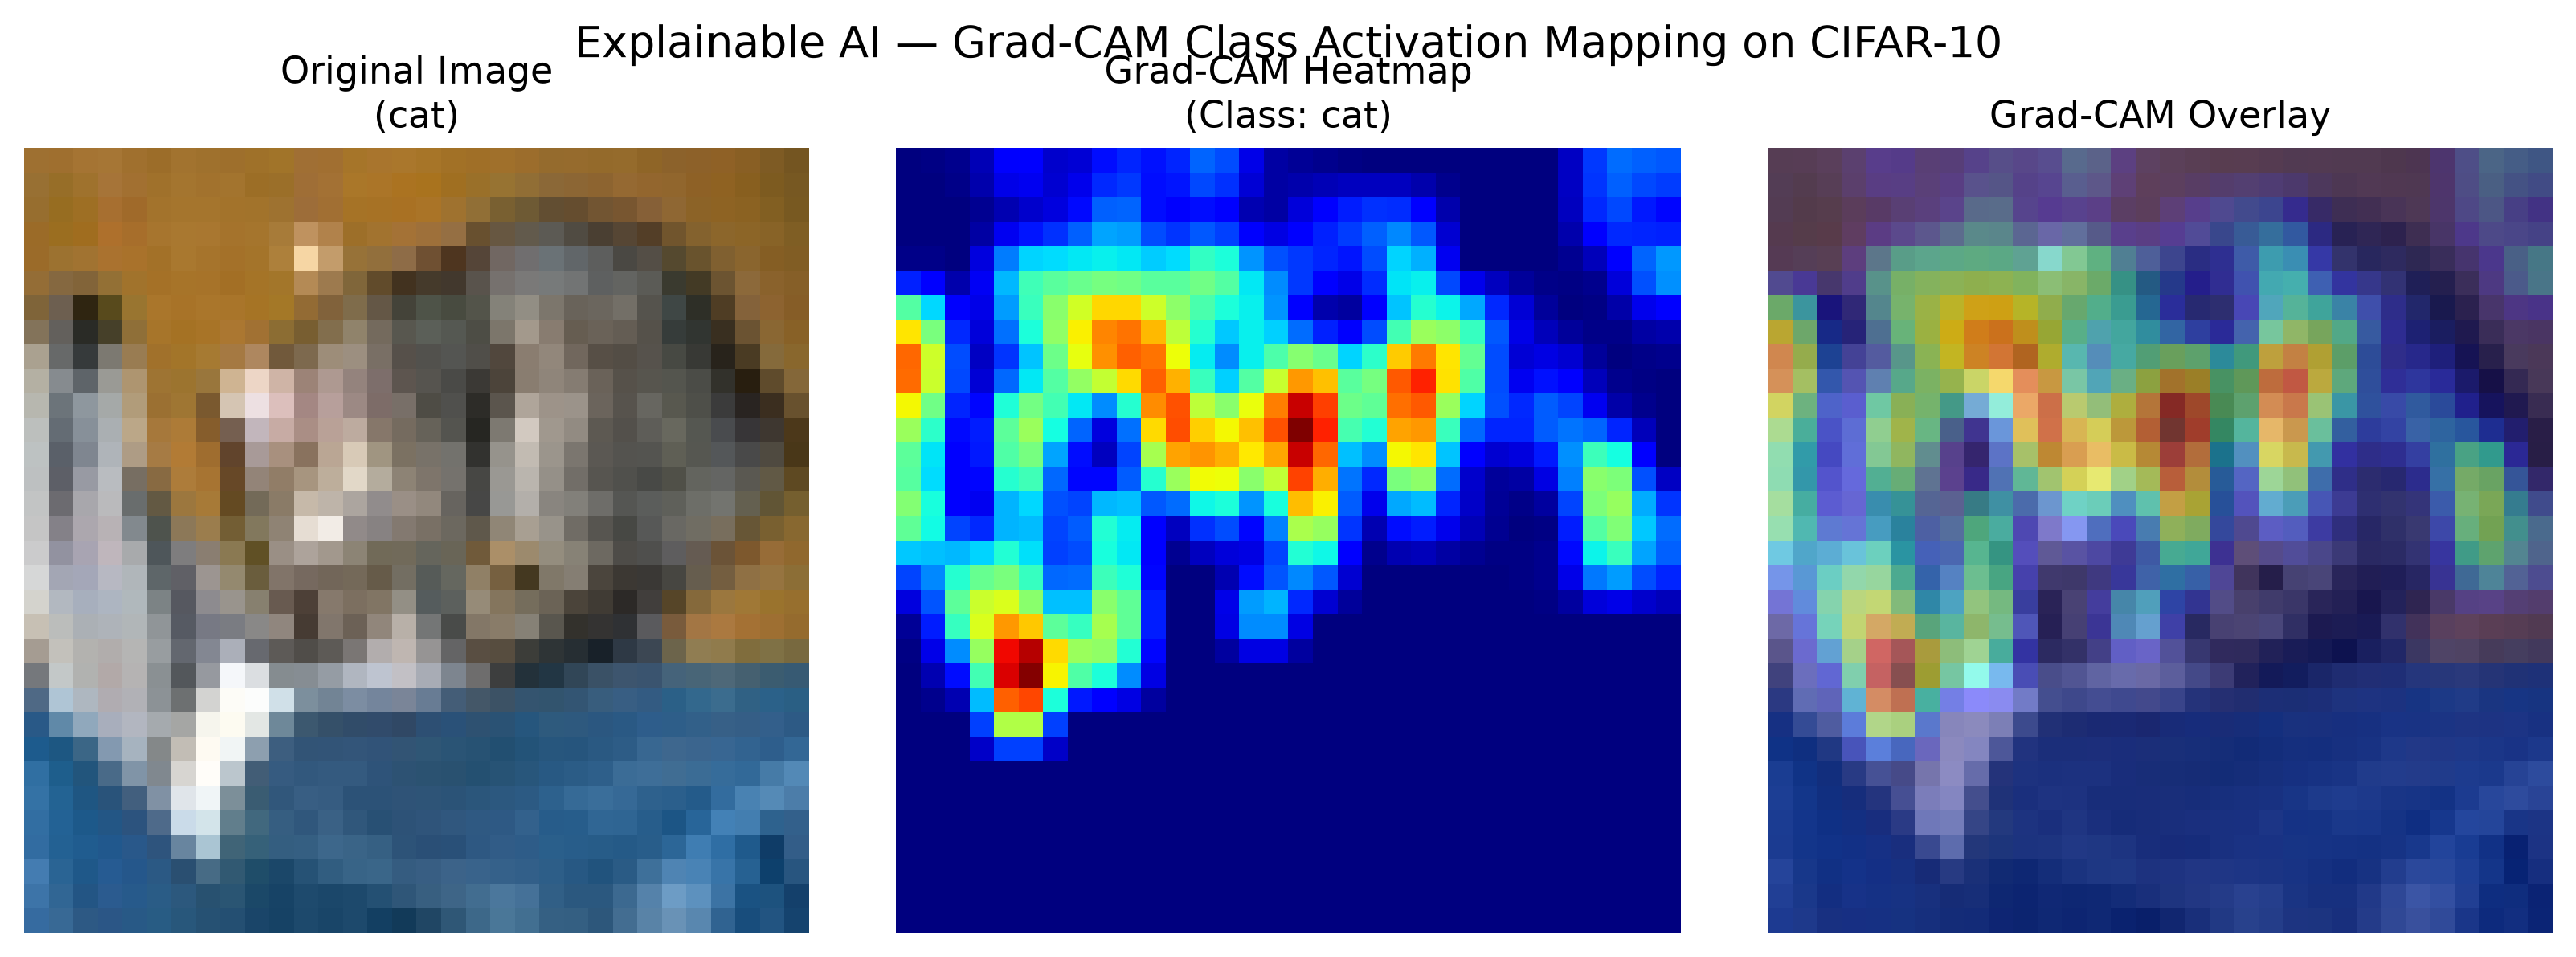

Grad-CAM visualization saved to: outputs/grad_cam_visualization.png


In [8]:
heatmap, explained_class = grad_cam.generate_heatmap(input_batch, target_class=pred_label)

raw_np = raw_img.permute(1, 2, 0).numpy()

# Colormap overlay
cmap = plt.get_cmap("jet")
heatmap_colored = cmap(heatmap)[:, :, :3]  # Drop alpha channel
overlay = 0.55 * raw_np + 0.45 * heatmap_colored
overlay = np.clip(overlay, 0, 1)

# Plot 3-panel explanation figure
fig, axes = plt.subplots(1, 3, figsize=(11, 4), dpi=300)

axes[0].imshow(raw_np)
axes[0].set_title(f"Original Image\n({classes[true_label]})", fontsize=11)
axes[0].axis("off")

axes[1].imshow(heatmap, cmap="jet")
axes[1].set_title(f"Grad-CAM Heatmap\n(Class: {classes[explained_class]})", fontsize=11)
axes[1].axis("off")

axes[2].imshow(overlay)
axes[2].set_title("Grad-CAM Overlay", fontsize=11)
axes[2].axis("off")

plt.suptitle("Explainable AI — Grad-CAM Class Activation Mapping on CIFAR-10", fontsize=13)
plt.tight_layout()

gradcam_out_path = OUTPUT_DIR / "grad_cam_visualization.png"
plt.savefig(gradcam_out_path)
plt.show()
print(f"Grad-CAM visualization saved to: {gradcam_out_path}")


---
### 10. Analyzing Attentive Regions and Model Explanations
- **Region Focus**: The warmest regions in the heatmap (red and yellow tones) correspond directly to discriminative physical attributes of the object (such as the fuselage and wing contours of the airplane), while background sky regions receive minimal attention.
- **Verification of Rational Decision-Making**: This confirms that the CNN is making predictions based on legitimate object features rather than spurious background artifacts (e.g., merely detecting a blue sky).


---
### 11. Limitations of Grad-CAM
1. **Coarse Spatial Resolution**: Because the final convolutional feature maps are downsampled ($8 \times 8$ from $32 \times 32$), Grad-CAM highlights broad general regions rather than fine pixel boundaries.
2. **Multiple Instances**: When multiple instances of the same object class appear in one image, Grad-CAM can blur their boundaries into a single unified heat blob.
3. **Plausibility vs. Faithfulness**: A heatmap may appear intuitive to human observers (plausible) while only partially reflecting the actual internal multi-layer causal mechanisms of the neural network (faithful).
